# Audio deployment: saved policy, thresholds and recording boundaries

This notebook runs the selected trained head and postprocessing on authentic **development** embeddings. It measures threshold errors, recording-safe filtering, serialized replay and cached inference time. It does not select thresholds, fit a model, open test data, or allocate the audio encoder. Cached timing excludes waveform decoding and PANNs feature extraction; the separate real-waveform cloud proof is shown at the end. The policy uses future context, so it is not a causal real-time detector.

In [1]:
from pathlib import Path
import sys,json,time,hashlib,math
import numpy as np
import pandas as pd
import torch
from torch import nn
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from overlap_audio.postprocess import validate_bundle, aligned_cache
from overlap_audio.natural import scores
# Only small trained heads; no encoder allocation.
torch.set_num_threads(2)
checkpoint=ROOT/'models/postprocess-v5/selected.pt'
receipt=json.loads((ROOT/'docs/production-checkpoint-receipt.json').read_text())
assert hashlib.sha256(checkpoint.read_bytes()).hexdigest()==receipt['production_sha256']
bundle=validate_bundle(torch.load(checkpoint,map_location='cpu',weights_only=True))
metadata=json.loads((ROOT/'data/features/five-second-cache/metadata.json').read_text())
x,y,mask,ids,seconds=aligned_cache(ROOT/'data/features/five-second-cache','validation',metadata)
classes=bundle['classes'];thresholds=bundle['thresholds'].numpy()
assert classes==metadata['classes'] and len(bundle['components'])==1
print({'development_seconds':len(x),'recordings':len(set(ids)),'classes':len(classes),'checkpoint_sha256':receipt['production_sha256'],'test_loaded':False})


{'development_seconds': 2163, 'recordings': 10, 'classes': 17, 'checkpoint_sha256': 'd082cb659e8ab94b9661fca741630cf12e09b951aa7ec74a544deceb7792c689', 'test_loaded': False}


## The deployed calculations
The readable definitions below match production: normalization, trained sigmoid head, convex score combination and filtering that resets at recording boundaries or missing seconds. Targets enter only the diagnostic cells afterward.

In [2]:
class Head(nn.Module):
    def __init__(self, classes, hidden=0, dropout=.3):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(2048,hidden),nn.ReLU(),nn.Dropout(dropout),nn.Linear(hidden,classes)) if hidden else nn.Linear(2048,classes)

    def forward(self, x):
        return self.layers(x)

def predict_head(model, x):
    model.eval()
    with torch.inference_mode():
        return torch.cat([torch.sigmoid(model(batch)) for batch in x.split(256)]).cpu()

In [3]:
def checked_probabilities(probability):
    p=np.asarray(probability,dtype=np.float32)
    if p.ndim!=2 or not len(p) or not np.isfinite(p).all() or not ((p>=0)&(p<=1)).all():
        raise ValueError('Expected nonempty finite probability matrix')
    return p

def convex_mix(probabilities,weights):
    values=np.asarray(probabilities,dtype=np.float32)
    w=np.asarray(weights,dtype=np.float64)
    if values.ndim!=3 or w.shape!=(len(values),) or not np.isfinite(w).all() or (w<0).any() or not np.isclose(w.sum(),1,atol=1e-8,rtol=0):
        raise ValueError('Ensemble weights must be finite, nonnegative and sum to one')
    for p in values:checked_probabilities(p)
    return np.clip(np.einsum('k,knc->nc',w,values),0,1).astype(np.float32)

def temporal_filter(probability,record_ids,seconds,spec):
    """No targets/masks enter filtering. Never cross records or missing seconds."""
    p=checked_probabilities(probability);ids=np.asarray(record_ids);t=np.asarray(seconds)
    if ids.shape!=(len(p),) or t.shape!=(len(p),) or not np.isfinite(t).all() or (t<0).any() or not (t==np.floor(t)).all() or any(not str(x) for x in ids):
        raise ValueError('Invalid recording/time alignment')
    if np.any((ids[1:]==ids[:-1])&(t[1:]<=t[:-1])):raise ValueError('Recording seconds must increase strictly')
    kind=spec.get('kind')
    if kind not in ['none','box','ewma']:raise ValueError('Unknown temporal filter')
    width=spec.get('width',1);alpha=spec.get('alpha',1.)
    if kind=='box' and (not isinstance(width,int) or width<1 or width%2!=1):raise ValueError('Box width must be a positive odd integer')
    if kind=='ewma' and (not math.isfinite(alpha) or not 0<alpha<=1):raise ValueError('EWMA alpha must be in (0,1]')
    if kind=='none':return p.copy()
    edges=np.r_[0,np.where((ids[1:]!=ids[:-1])|(t[1:]!=t[:-1]+1))[0]+1,len(p)]
    output=np.empty_like(p)
    for lo,hi in zip(edges[:-1],edges[1:]):
        block=p[lo:hi].astype(np.float64)
        if kind=='box':
            cumulative=np.vstack([np.zeros((1,p.shape[1])),block.cumsum(0)])
            center=np.arange(len(block));left=np.maximum(0,center-width//2);right=np.minimum(len(block),center+width//2+1)
            output[lo:hi]=(cumulative[right]-cumulative[left])/(right-left)[:,None]
        else:
            state=block[0];output[lo]=state
            for index in range(1,len(block)):
                state=alpha*block[index]+(1-alpha)*state;output[lo+index]=state
    return np.clip(output,0,1)

def apply_policy(component_probabilities,policy,record_ids,seconds):
    branches=[]
    for branch in policy['branches']:
        p=convex_mix(component_probabilities,branch['weights'])
        for spec in branch.get('filters',[]):p=temporal_filter(p,record_ids,seconds,spec)
        branches.append(p)
    p=convex_mix(np.stack(branches),policy['mix_weights'])
    for spec in policy.get('filters',[]):p=temporal_filter(p,record_ids,seconds,spec)
    return p

def component_predictions(component,features,device='cpu'):
    x=torch.as_tensor(features,dtype=torch.float32)
    count=len(component['classes']);mean=component['mean'];std=component['std']
    if x.ndim!=2 or x.shape[1]!=2048 or mean.shape!=(2048,) or std.shape!=(2048,) or not torch.isfinite(x).all() or not torch.isfinite(mean).all() or not torch.isfinite(std).all() or not (std>0).all():
        raise ValueError('Invalid component features or normalization')
    model=Head(count,component['config']['hidden'],component['config'].get('dropout',.3)).to(device);model.load_state_dict(component['state_dict'])
    return predict_head(model,((x-mean)/std).to(device)).numpy()

In [4]:
def deploy(features,record_ids,times,selected):
    component_probabilities=np.stack([component_predictions(c,features) for c in selected['components']])
    return apply_policy(component_probabilities,selected['policy'],record_ids,times)
p=deploy(x,ids,seconds,bundle)
restored=validate_bundle(torch.load(checkpoint,map_location='cpu',weights_only=True))
replay=deploy(x,ids,seconds,restored)
assert np.array_equal(p,replay)
metrics=scores(torch.from_numpy(y),torch.from_numpy(p),torch.from_numpy(mask),bundle['thresholds'],classes)
assert abs(metrics['macro_ap_supported']-receipt['actual_cli_validation_ap'])<1e-12
print({'saved_reload_max_difference':float(np.max(abs(p-replay))),'development_AP':metrics['macro_ap_supported'],'lookahead_seconds':bundle['lookahead_seconds'],'encoder_allocated':False})
print('Frozen policy:',bundle['policy'])


{'saved_reload_max_difference': 0.0, 'development_AP': 0.4767020190677916, 'lookahead_seconds': 3, 'encoder_allocated': False}
Frozen policy: {'name': "central-0-final-{'kind': 'box', 'width': 3}", 'branches': [{'weights': [1], 'filters': []}], 'mix_weights': [1], 'filters': [{'kind': 'box', 'width': 3}]}


## Where the fixed thresholds fail
Only known labels count. Training used soft targets; diagnostic binary targets use the original strict `> 0.5` rule. Unknown labels are excluded, rather than counted as negatives. These are reused development diagnostics, not a fresh generalization estimate. Thresholds stay unchanged.

,threshold,known,positive,TP,FP,FN,precision,recall,false_positive_rate
class,,,,,,,,,
announcement,0.50,363,0,0,17,0,0.000000,NaN,0.046832
birds_singing,0.60,384,212,172,8,40,0.955556,0.811321,0.046512
brakes_squeaking,0.80,541,10,3,101,7,0.028846,0.300000,0.190207
car,0.65,925,690,609,85,81,0.877522,0.882609,0.361702
cash register beeping,0.50,363,0,0,362,0,0.000000,NaN,0.997245
children voices,0.75,2163,7,4,22,3,0.153846,0.571429,0.010204
coffee machine,0.50,425,0,0,425,0,0.000000,NaN,1.000000
cutlery and dishes,0.85,425,25,13,48,12,0.213115,0.520000,0.120000
door opens/closes,0.50,450,1,1,438,0,0.002278,1.000000,0.975501


{'unknown_class_seconds_excluded': 23793, 'fixed_thresholds_reselected': False}


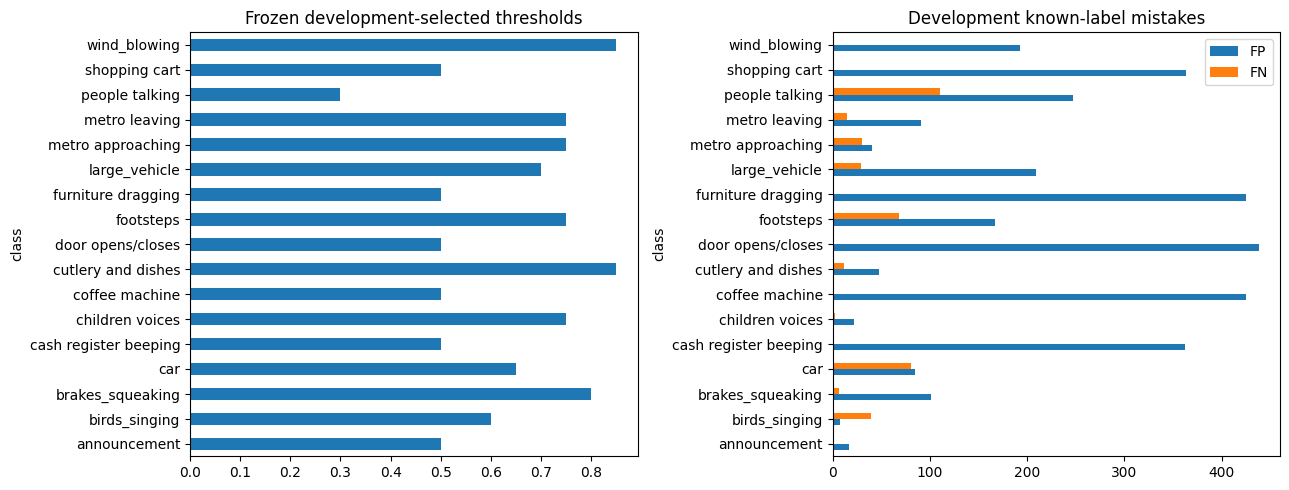

In [5]:
known=mask.astype(bool); truth=y>0.5; decision=p>=thresholds
rows=[]
for j,name in enumerate(classes):
    valid=known[:,j];t=truth[valid,j];d=decision[valid,j]
    tp=int((t&d).sum());fp=int((~t&d).sum());fn=int((t&~d).sum());tn=int((~t&~d).sum())
    rows.append({'class':name,'threshold':float(thresholds[j]),'known':int(valid.sum()),'positive':int(t.sum()),'TP':tp,'FP':fp,'FN':fn,
                 'precision':tp/(tp+fp) if tp+fp else np.nan,'recall':tp/(tp+fn) if tp+fn else np.nan,'false_positive_rate':fp/(fp+tn) if fp+tn else np.nan})
errors=pd.DataFrame(rows).set_index('class')
display(errors)
print({'unknown_class_seconds_excluded':int((~known).sum()),'fixed_thresholds_reselected':False})
fig,axes=plt.subplots(1,2,figsize=(13,5))
errors['threshold'].plot.barh(ax=axes[0],title='Frozen development-selected thresholds')
errors[['FP','FN']].plot.barh(ax=axes[1],title='Development known-label mistakes')
fig.tight_layout();display(fig);plt.close(fig)


## Recording boundaries are part of inference
The same policy applied independently to each contiguous recording must equal the full aligned result. This verifies that neighboring recordings do not supply smoothing context. Head inference with different batch shapes may differ by floating-point rounding; the filter itself must match exactly on identical input probabilities. A probability trace is diagnostic only; no new filter width is chosen.

{'independent_head_batch_rounding_max_difference': 1.1920928955078125e-07, 'filter_boundary_replay_max_difference': 0.0, 'recording_blocks': 10}


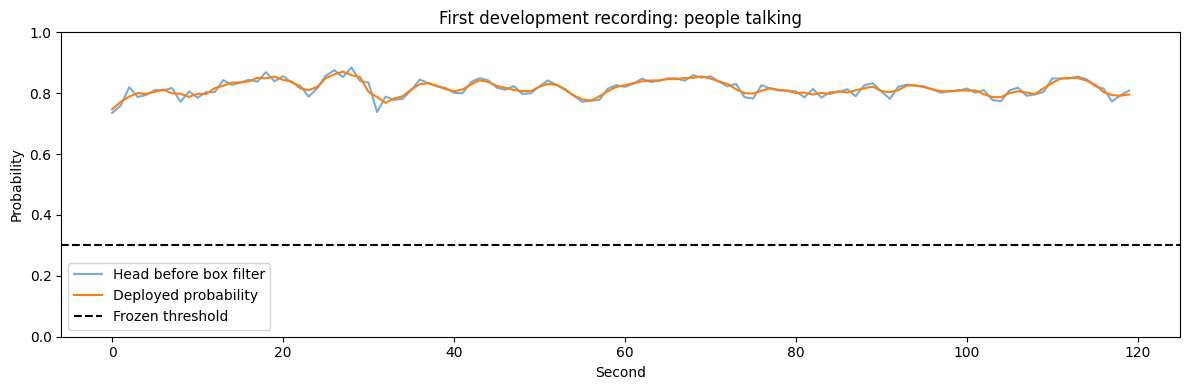

In [6]:
edges=np.r_[0,np.where(ids[1:]!=ids[:-1])[0]+1,len(ids)]
independent=np.concatenate([deploy(x[a:b],ids[a:b],seconds[a:b],bundle) for a,b in zip(edges[:-1],edges[1:])])
head_batch_delta=float(np.max(abs(p-independent)))
assert head_batch_delta<1e-6
all_components=np.stack([component_predictions(c,x) for c in bundle['components']])
whole=apply_policy(all_components,bundle['policy'],ids,seconds)
separate=np.concatenate([apply_policy(all_components[:,a:b],bundle['policy'],ids[a:b],seconds[a:b]) for a,b in zip(edges[:-1],edges[1:])])
assert np.array_equal(whole,separate)
print({'independent_head_batch_rounding_max_difference':head_batch_delta,'filter_boundary_replay_max_difference':float(np.max(abs(whole-separate))),'recording_blocks':len(edges)-1})
j=int(np.argmax(errors['positive'].to_numpy()));a,b=edges[:2];stop=min(b,a+120)
raw=component_predictions(bundle['components'][0],x[a:stop])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(seconds[a:stop],raw[:,j],alpha=.6,label='Head before box filter')
ax.plot(seconds[a:stop],p[a:stop,j],label='Deployed probability')
ax.axhline(thresholds[j],color='black',linestyle='--',label='Frozen threshold')
ax.set(title='First development recording: '+classes[j],xlabel='Second',ylabel='Probability',ylim=(0,1));ax.legend();fig.tight_layout();display(fig);plt.close(fig)


## Cached-head latency and real-waveform evidence
Measured timings include head reconstruction, feature normalization, head inference and policy application for the entire development cohort. They exclude encoder and I/O, and depend on this host. Three-second lookahead is algorithmic delay and cannot be inferred from wall-clock timing.

,trial,seconds
0,1,0.190609
1,2,0.154398
2,3,0.120273
3,4,0.154540
4,5,0.138641
5,6,0.212088
6,7,0.177595
7,8,0.168035


{'cohort_seconds': 2163, 'median_cached_seconds': 0.16128765000030398, 'p95_cached_seconds': 0.20457064998772692, 'torch_threads': 2, 'waveform_end_to_end_timing': False}


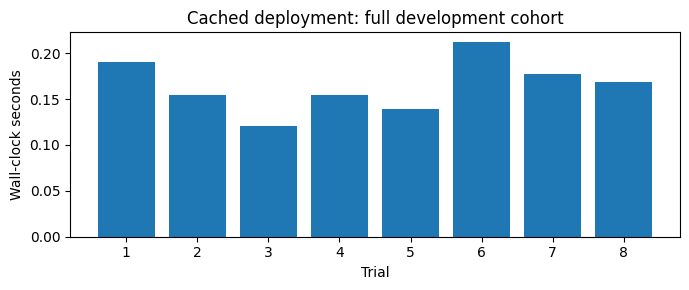

,rows,probabilities,finite_in_unit_interval,probe_source_record,accuracy_claim,lookahead_seconds,checkpoint_replay_max_difference
0,5,85,True,cafe_restaurant_04,False,3,0.0


In [7]:
timings=[]
for _ in range(8):
    start=time.perf_counter();deploy(x,ids,seconds,bundle);timings.append(time.perf_counter()-start)
timing=pd.DataFrame({'trial':np.arange(1,9),'seconds':timings})
display(timing)
print({'cohort_seconds':len(x),'median_cached_seconds':float(np.median(timings)),'p95_cached_seconds':float(np.percentile(timings,95)),'torch_threads':torch.get_num_threads(),'waveform_end_to_end_timing':False})
fig,ax=plt.subplots(figsize=(7,3));ax.bar(timing.trial,timing.seconds);ax.set(xlabel='Trial',ylabel='Wall-clock seconds',title='Cached deployment: full development cohort');fig.tight_layout();display(fig);plt.close(fig)
proof=json.loads((ROOT/'docs/postprocess-v5-actual-inference-proof.json').read_text())
display(pd.json_normalize(proof))


The real-waveform receipt is from the completed private cloud run, not an encoder execution in this notebook. Rare classes and unseen recording conditions remain weak points. A high probability is not a calibrated confidence guarantee; the fixed development thresholds do not establish safe alarm rates in a new environment.